# 01 · First model (R3, Output 4)
**Skills:** Week 1 train/test, Week 2 classification and overfitting, Week 4 data health, Week 5 pipelines and leakage.

**Run all cells (Run All in VS Code).** The CHECK lines print PASS or TODO.
The grey boxes marked **YOUR TURN** are for *your* words: they are the thinking the marks are for.

In [1]:
# SETUP: make the project's own code importable, whatever folder VS Code started in.
import sys, pathlib
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "src").exists())
sys.path.insert(0, str(ROOT))
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)
print("Project root:", ROOT)

Project root: /Users/admin/Desktop/smart-vitals-ipms


## 1 · The model in one line
**YOUR TURN:** write it: *what it decides, from what, the main measure and the target.*

> _e.g. "Classify each reading as Normal / Warning / Critical from the vitals and 5-minute trends; main measure: recall for Critical on unseen patients; target ≥ 0.90."_

## 2 · Load the data and check its health (Week 5)

In [2]:
from src import config, pipeline as P
raw = pd.read_csv(config.DATA_PATH)
print(raw.shape)
raw.head()

(26876, 14)


,reading_id,patient_id,timestamp,heart_rate,spo2,systolic,diastolic,temperature,glucose,minute,fault,true_label,risk_group,has_diabetes
0,T001-0000,T001,2026-01-01T08:00:00,65.0,96.6,145.0,84.0,36.7,143.0,0,NaN,Normal,Medium,True
1,T001-0007,T001,2026-01-01T08:07:00,60.0,96.3,140.0,82.0,36.6,140.0,7,NaN,Normal,Medium,True
2,T001-0008,T001,2026-01-01T08:08:00,63.0,96.4,NaN,83.0,36.7,134.0,8,missing_vital,Normal,Medium,True
3,T001-0009,T001,2026-01-01T08:09:00,66.0,96.9,142.0,81.0,36.7,138.0,9,NaN,Normal,Medium,True
4,T001-0010,T001,2026-01-01T08:10:00,67.0,96.9,141.0,82.0,36.6,138.0,10,NaN,Normal,Medium,True


In [3]:
health = P.data_health(raw)
for k, v in health.items():
    print(f"{k:22s} {v}")
print()
print("Share of each true label:")
print((raw["true_label"].value_counts(normalize=True) * 100).round(1).astype(str) + " %")

rows                   26876
patients               80
duplicate_ids          0
missing_pct            {'heart_rate': 0.35, 'spo2': 0.37, 'systolic': 0.35, 'diastolic': 0.42, 'temperature': 0.39}
out_of_range_values    355

Share of each true label:
true_label
Normal      92.6 %
Warning      5.3 %
Critical     2.1 %
Name: proportion, dtype: str


In [4]:
# CHECK: is Critical rare? (If so, accuracy will mislead us.)
share = (raw["true_label"] == "Critical").mean()
print("PASS: Critical is rare, so accuracy alone will mislead." if share < 0.10 else "TODO: Critical is not rare in your data")

PASS: Critical is rare, so accuracy alone will mislead.


**YOUR TURN:** what in the health report would worry you, and how will the pipeline deal with it?

## 3 · Clean and build features (the same functions the API uses)

In [5]:
df = P.clean_and_featurise(raw)
print("impossible values blanked:", int(df["n_glitches"].sum()), "| stuck-sensor values blanked:", int(df["n_stuck"].sum()))
print("rows still missing a heart rate after cleaning:", int(df["heart_rate"].isna().sum()))
df[["patient_id", "timestamp", "heart_rate", "hr_mean5", "hr_change5", "spo2", "true_label"]].head(8)

impossible values blanked: 355 | stuck-sensor values blanked: 213
rows still missing a heart rate after cleaning: 52


,patient_id,timestamp,heart_rate,hr_mean5,hr_change5,spo2,true_label
0,T001,2026-01-01 08:00:00,65.0,65.000000,NaN,96.6,Normal
1,T001,2026-01-01 08:07:00,60.0,62.500000,NaN,96.3,Normal
2,T001,2026-01-01 08:08:00,63.0,62.666667,NaN,96.4,Normal
3,T001,2026-01-01 08:09:00,66.0,63.500000,NaN,96.9,Normal
4,T001,2026-01-01 08:10:00,67.0,64.200000,2.0,96.9,Normal
5,T001,2026-01-01 08:11:00,66.0,64.400000,6.0,97.0,Normal
6,T001,2026-01-01 08:12:00,65.0,65.400000,2.0,96.3,Normal
7,T001,2026-01-01 08:13:00,66.0,66.000000,0.0,96.3,Normal


## 4 · Keep back patients the model has never seen

In [6]:
from src import model as M
from src.pipeline import FEATURES
train, test = M.split_by_patient(df)
overlap = set(train.patient_id) & set(test.patient_id)
print(len(train.patient_id.unique()), "training patients,", len(test.patient_id.unique()), "test patients")
print("PASS: no patient is in both sets" if not overlap else "FIX: patients appear in both sets")
X_tr, y_tr, X_te, y_te = train[FEATURES], train["true_label"], test[FEATURES], test["true_label"]

60 training patients, 20 test patients
PASS: no patient is in both sets


## 5 · Baseline, then two real models

In [7]:
models = {"baseline (always Normal)": M.make_baseline(),
          "logistic regression": M.make_logreg(),
          "random forest": M.make_forest()}
results = {}
for name, m in models.items():
    m.fit(X_tr, y_tr)
    results[name] = M.evaluate(m, X_te, y_te)
table = pd.DataFrame({n: {"accuracy": r["accuracy"], "macro F1": r["macro_f1"],
                          "precision Critical": r["precision"]["Critical"],
                          "recall Critical": r["recall"]["Critical"], "F1 Critical": r["f1"]["Critical"]}
                      for n, r in results.items()}).T.round(3)
table

,accuracy,macro F1,precision Critical,recall Critical,F1 Critical
baseline (always Normal),0.901,0.316,0.000,0.000,0.000
logistic regression,0.953,0.807,0.598,0.798,0.684
random forest,0.989,0.948,0.944,0.899,0.921


In [8]:
base = results["baseline (always Normal)"]
print(f"The baseline is right {base['accuracy']:.0%} of the time but finds {base['recall_critical']:.0%} of Critical readings.")

The baseline is right 90% of the time but finds 0% of Critical readings.


**YOUR TURN:** why is accuracy the wrong main measure here? Which model do you choose, and why (cite the numbers)?

## 6 · Confusion matrices (Output 4)

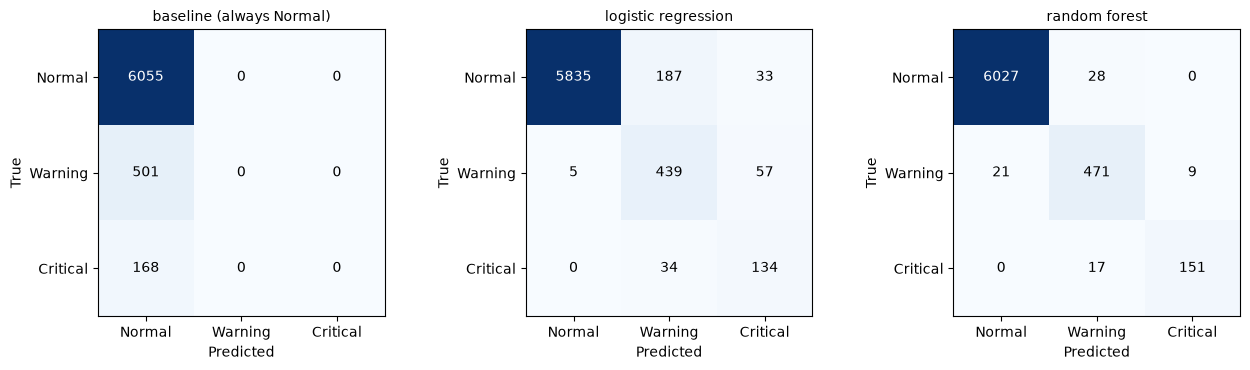

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (name, r) in zip(axes, results.items()):
    cm = np.array(r["confusion_matrix"])
    ax.imshow(cm, cmap="Blues"); ax.set_title(name, fontsize=10)
    ax.set_xticks(range(3), config.LABELS); ax.set_yticks(range(3), config.LABELS)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout(); plt.show()

## 7 · Is a perfect score a warning? Row split vs patient split (Week 5)

In [10]:
r_train, r_test = M.split_random_rows(df)
leaky = M.make_forest().fit(r_train[FEATURES], r_train["true_label"])
leaky_acc = M.evaluate(leaky, r_test[FEATURES], r_test["true_label"])["accuracy"]
print(f"forest, random-row split : accuracy {leaky_acc:.3f}   <- the model has already met these patients")
print(f"forest, patient split    : accuracy {results['random forest']['accuracy']:.3f}   <- honest")

forest, random-row split : accuracy 0.995   <- the model has already met these patients
forest, patient split    : accuracy 0.989   <- honest


## 8 · What did the forest rely on?

In [11]:
forest = models["random forest"]
imp = pd.Series(forest.named_steps["model"].feature_importances_, index=FEATURES).sort_values(ascending=False)
imp.head(8).round(3)

heart_rate     0.263
hr_mean5       0.170
systolic       0.113
sys_mean5      0.081
spo2           0.081
diastolic      0.079
spo2_mean5     0.060
temperature    0.059
dtype: float64

**YOUR TURN (limitation):** the labels were made by a points rule on the same vitals the model sees. What does that mean for how impressive these numbers are? (See `docs/assumptions.md`.)

## 9 · Target check

In [12]:
target = 0.90
r = results["random forest"]["recall_critical"]
print(f"recall for Critical = {r:.3f} (target {target})")
print("PASS: target met on unseen patients" if r >= target else "TODO: below target - what could you try? (more data, features, a Critical threshold)")

recall for Critical = 0.899 (target 0.9)
TODO: below target - what could you try? (more data, features, a Critical threshold)


Save the chosen model for the API with `python -m src.train` (it also writes `docs/results/model_comparison.md`).